# Extractive Text Summarization

Open in [Google Colab](https://colab.research.google.com/github/febse/ta2025/blob/main/02-04-Extractive-Summarization.ipynb)

The goal in extractive summarization is to select a couple (a predefined number) of sentences from a document. That
are in some sense "representative" of the document. We will look into two simple approaches that rank sentences
according to their TF-IDF representation.

For both approaches we will treat a single document as a corpus sentences and will
compute the TF-IDF matrix using the sentences as documents and the words just as in the previous
examples. We will look into two approaches to assigning a score: a simple average of the 
sentence's word scores and the TextRank score.

- Split the document into sentences (sentence tokenization)
- Assign a score to each sentence using its TF-IDF representation.
- Pick the top N sentences based on the scores

- Score = Average (non-zero TF-IDF of words in the sentence) 
    - Unimportant words have smaller values in the TF-IDF matrix
    - Important words appearing more often in the sentence will have an even higher score.
    - Average instead of just summing to normalize for sentence length. 
    - Non-zero elements because the TF-IDF is very sparse and don't want to choose based on variety of words

- TextRank score
    - See the discussion below


In [25]:
import pandas as pd
import numpy as np
import textwrap
import nltk
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import networkx as nx
import matplotlib.pyplot as plt

In [26]:
nltk.download("punkt")
nltk.download('punkt_tab')
nltk.download("stopwords")

[nltk_data] Downloading package punkt to /home/amarov/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /home/amarov/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /home/amarov/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [27]:
df = pd.read_csv("https://github.com/febse/data/raw/refs/heads/main/ta/BBC%20News%20Train.csv.zip")
df.head()

,ArticleId,Text,Category
0,1833,worldcom ex-boss launches defence lawyers defe...,business
1,154,german business confidence slides german busin...,business
2,1101,bbc poll indicates economic gloom citizens in ...,business
3,1976,lifestyle governs mobile choice faster bett...,tech
4,917,enron bosses in $168m payout eighteen former e...,business


In [28]:
doc = df.loc[df["ArticleId"] == 1833].iloc[0]

print(textwrap.fill(doc["Text"], replace_whitespace=False, fix_sentence_endings=True))

worldcom ex-boss launches defence lawyers defending former worldcom
chief bernie ebbers against a battery of fraud charges have called a
company whistleblower as their first witness.  cynthia cooper
worldcom s ex-head of internal accounting  alerted directors to
irregular accounting practices at the us telecoms giant in 2002. her
warnings led to the collapse of the firm following the discovery of an
$11bn (£5.7bn) accounting fraud.  mr ebbers has pleaded not guilty to
charges of fraud and conspiracy.  prosecution lawyers have argued that
mr ebbers orchestrated a series of accounting tricks at worldcom
ordering employees to hide expenses and inflate revenues to meet wall
street earnings estimates.  but ms cooper  who now runs her own
consulting business  told a jury in new york on wednesday that
external auditors arthur andersen had approved worldcom s accounting
in early 2001 and 2002. she said andersen had given a  green light  to
the procedures and practices used by worldcom.  mr ebb

In [29]:
# no-ex-class
type(doc["Text"])

str

In [30]:
from nltk.tokenize import sent_tokenize

sents = sent_tokenize(doc["Text"])
sents

['worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against a battery of fraud charges have called a company whistleblower as their first witness.',
 'cynthia cooper  worldcom s ex-head of internal accounting  alerted directors to irregular accounting practices at the us telecoms giant in 2002. her warnings led to the collapse of the firm following the discovery of an $11bn (£5.7bn) accounting fraud.',
 'mr ebbers has pleaded not guilty to charges of fraud and conspiracy.',
 'prosecution lawyers have argued that mr ebbers orchestrated a series of accounting tricks at worldcom  ordering employees to hide expenses and inflate revenues to meet wall street earnings estimates.',
 'but ms cooper  who now runs her own consulting business  told a jury in new york on wednesday that external auditors arthur andersen had approved worldcom s accounting in early 2001 and 2002. she said andersen had given a  green light  to the procedures and practices used by w

In [31]:
vectorizer = TfidfVectorizer(stop_words=stopwords.words('english'))

X = vectorizer.fit_transform(sents)
pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out()).head()

,11bn,2001,2002,2004,75bn,7bn,85,accounting,adjustments,agreed,...,verizon,wall,warnings,wednesday,week,whistleblower,witness,worldcom,years,york
0,0.00000,0.000000,0.000000,0.0,0.0,0.00000,0.0,0.000000,0.0,0.0,...,0.0,0.000000,0.00000,0.000000,0.0,0.253766,0.217937,0.262533,0.0,0.000000
1,0.20595,0.000000,0.176872,0.0,0.0,0.20595,0.0,0.381491,0.0,0.0,...,0.0,0.000000,0.20595,0.000000,0.0,0.000000,0.000000,0.106533,0.0,0.000000
2,0.00000,0.000000,0.000000,0.0,0.0,0.00000,0.0,0.000000,0.0,0.0,...,0.0,0.000000,0.00000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000
3,0.00000,0.000000,0.000000,0.0,0.0,0.00000,0.0,0.147399,0.0,0.0,...,0.0,0.238723,0.00000,0.000000,0.0,0.000000,0.000000,0.123485,0.0,0.000000
4,0.00000,0.165825,0.165825,0.0,0.0,0.00000,0.0,0.119221,0.0,0.0,...,0.0,0.000000,0.00000,0.193087,0.0,0.000000,0.000000,0.199758,0.0,0.193087


In [32]:
# no-ex-class
X.shape

(12, 137)

In [33]:
X = X.toarray()
scores = np.array([np.mean(row[row != 0]) for row in X])
print("Row-wise Mean of Non-zero Elements:\n", scores)

Row-wise Mean of Non-zero Elements:
 [0.2269258  0.1987996  0.36673461 0.21409173 0.18696719 0.30947282
 0.23131543 0.22443098 0.25194776 0.29554142 0.371702   0.31593632]


In [34]:
sort_idx = np.argsort(-scores)

In [35]:
print("Top sentences:\n")

for i in sort_idx[:5]:
  print(f"%.2f: %s" % (scores[i], sents[i]))

Top sentences:

0.37: worldcom emerged from bankruptcy protection in 2004  and is now known as mci.
0.37: mr ebbers has pleaded not guilty to charges of fraud and conspiracy.
0.32: last week  mci agreed to a buyout by verizon communications in a deal valued at $6.75bn.
0.31: mr ebber s lawyers have said he was unaware of the fraud  arguing that auditors did not alert him to any problems.
0.30: mr ebbers could face a jail sentence of 85 years if convicted of all the charges he is facing.


## TextRank

TextRank is an unsupervised keyword and sentence extraction algorithm that is inspired by PageRank, the Google page ranking algorithm in the 1990s and 2000s (@mihalcea2004textrank)

Before we can see how to apply TextRank to text summarization, we need to understand how PageRank works.
PageRank is a link analysis algorithm that assigns a numerical weighting to each element of a hyperlinked set of documents, such as the World Wide Web, with the purpose of "measuring" its relative importance within the set.


```{mermaid}
graph TD
    A[Page A] -->|Link| B[Page B]
    A -->|Link| C[Page C]
    B -->|Link| D[Page D]
    C -->|Link| D
    D -->|Link| A
    D -->|Link| E[Page E]
    E -->|Link| B
```


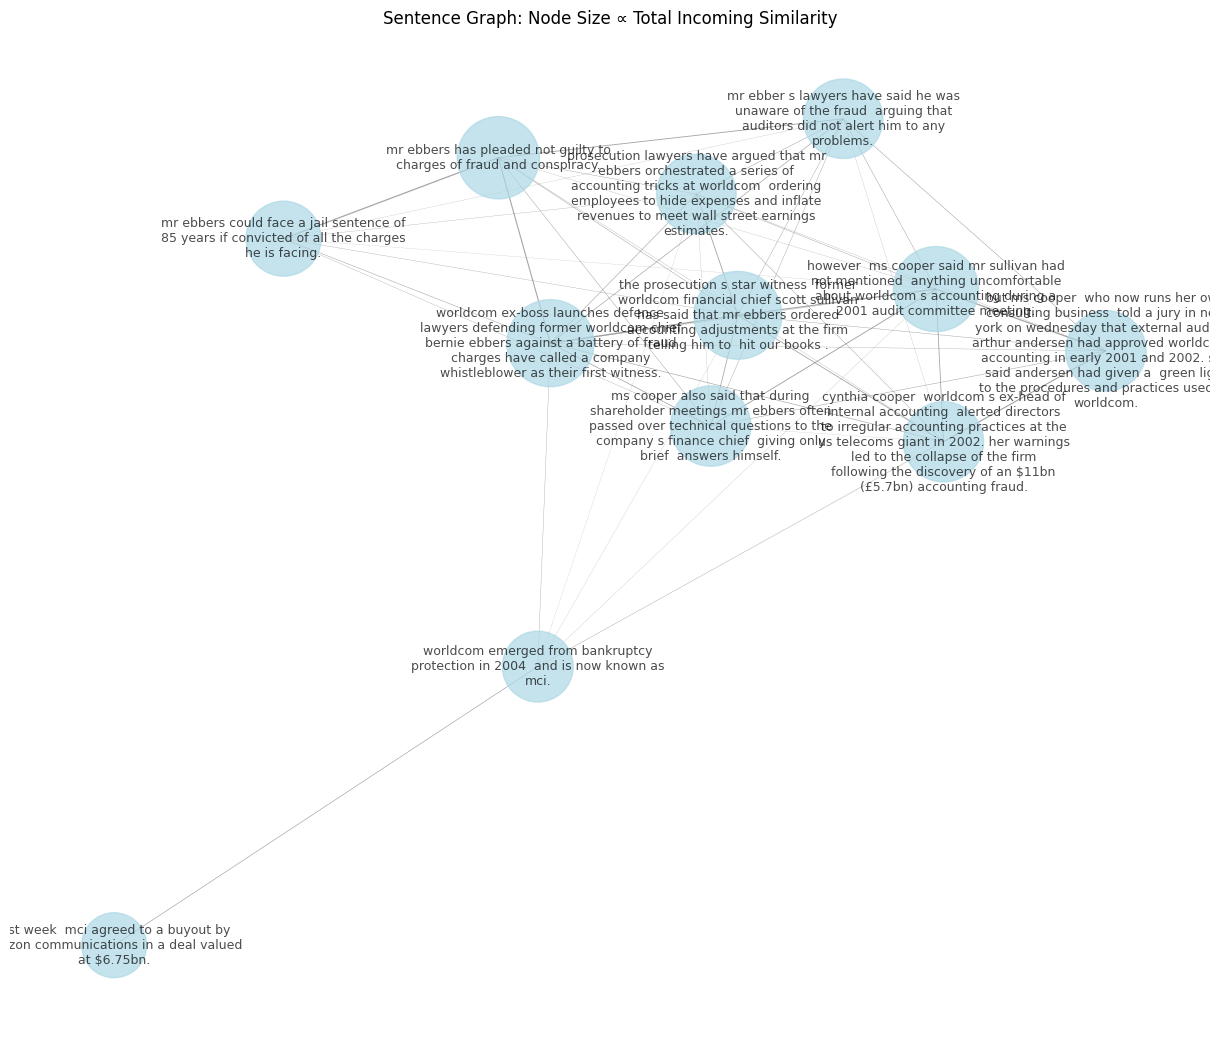

In [36]:
# no-ex-class
# Wrap sentences for display
wrapped_sents = [textwrap.fill(sent, width=40) for sent in sents]

# Compute cosine similarity matrix (X should be the TF-IDF matrix, already defined)
cos_sim = cosine_similarity(X)

G = nx.Graph()
for i, label in enumerate(wrapped_sents):
    G.add_node(i, label=label)

# Add edges with weights proportional to cosine similarity
for i in range(len(sents)):
    for j in range(i + 1, len(sents)):
        G.add_edge(i, j, weight=cos_sim[i, j])

# Draw the graph with edge width proportional to similarity
pos = nx.spring_layout(G, seed=42)
labels = nx.get_node_attributes(G, 'label')
edges = G.edges(data=True)
weights = [d['weight'] * 5 for (_, _, d) in edges]  # scale for visibility

# Node size proportional to total incoming similarity
node_sim = cos_sim.sum(axis=1)
node_sizes = node_sim * 4000 / node_sim.max()  # increased scale for visibility

plt.figure(figsize=(12, 10))
nx.draw(
    G, pos, with_labels=True, labels=labels,
    node_size=node_sizes, node_color='lightblue', font_size=9,
    font_color='black', alpha=0.7,
    width=weights, edge_color='gray'
)
plt.title("Sentence Graph: Node Size ∝ Total Incoming Similarity")
plt.show()

Let's take a walk through the web. We start at a random webpage and follow a random link on that page. On the next page, we again follow a randomly chosen link. We keep doing this for a long time. We can ask a question: what is the probability that we end up on a certain page?

We can view this walk as a Markov chain. Say that all pages are $n$ and let's assume that we can reach any page from any other page (though not 
with the same probability).

In [37]:
# no-ex-class
# print()

In [38]:
# no-ex-class
import nltk
from nltk.corpus import gutenberg

nltk.download('gutenberg')


[nltk_data] Downloading package gutenberg to /home/amarov/nltk_data...
[nltk_data]   Package gutenberg is already up-to-date!


True

In [39]:
# no-ex-class

alice = gutenberg.raw(fileids="carroll-alice.txt")

print(f"Text length: {len(alice)} characters")

# Remove non-word characters and spaces, lowercase

import re
alice_clean = re.sub(r'\s+', '', re.sub(r'[^\w\s]', '', alice)).lower()

print(f"Cleaned text length: {len(alice_clean)} characters")

# Convert to a sequence of consonants and vowels

alice_cv = re.sub(r'[aeiou]', 'V', re.sub(r'[^aeiou\s]', 'C', alice_clean))
alice_cv[:100]

Text length: 144395 characters
Cleaned text length: 107693 characters


'VCVCVCVCCVCCVCVCVCCVCCVCCVCCCCCVCVCCVCCVCCCCCCCCVCCVCVCVCCCCVCVCCVCCVCVVCVCVCVCCVCVCCVCCCVCVCCVCCCVC'

In [40]:
# no-ex-class
# Count the frequencies of vowels and consonants

from collections import Counter
cv_counts = Counter(alice_cv)
cv_counts

Counter({'C': 66212, 'V': 41481})

In [41]:
# no-ex-class
P_V = cv_counts['V'] / (cv_counts['V'] + cv_counts['C'])  # P(V)
P_C = cv_counts['C'] / (cv_counts['V'] + cv_counts['C'])  # P(C)

print(f"P(V): {P_V:.4f}, P(C): {P_C:.4f}")
# Count the frequencies of VV, CC, VC, CV

P(V): 0.3852, P(C): 0.6148


In [42]:
# no-ex-class
# Count the frequencies of VV, CC, VC, CV

cv_bigrams = [alice_cv[i:i+2] for i in range(len(alice_cv)-1)]
bigram_counts = Counter(cv_bigrams)
bigram_counts

Counter({'VC': 34838, 'CV': 34837, 'CC': 31374, 'VV': 6643})

In [43]:
V_to_C = 34838 / (34838 + 6643)  # P(V->C | V)
V_to_V = 6643 / (34838 + 6643)   # P(V->C | V)

C_to_C = 31374 / (31374 + 34837) # P(C->C | C)
C_to_V = 34837 / (31374 + 34837) # P(C->V | C)

print(f"P(V->V|V): {V_to_V:.2}, P(V->C|V): {V_to_C:.2}")
print(f"P(C->C|C): {C_to_C:.2}, P(C->V|C): {C_to_V:.2}")

P(V->V|V): 0.16, P(V->C|V): 0.84
P(C->C|C): 0.47, P(C->V|C): 0.53


In [44]:
# no-ex-class
# Count the frequencies of vowels and consonants

Let's now track the states of the Markov chain as we jump between vowels and consonants in "Alice's Adventures in Wonderland".

We perform a series of transitions between two states: Vowel (V) and Consonant (C). Let's denote the state we are in at step $t$ as $S_t$.
So $S_t = V$ means that at step $t$ we are at a vowel, and $S_t = C$ means we are at a consonant.

- We start by picking a state at random, say with equal probability:
  - $P(S_0 = V) = 0.5$
  - $P(S_0 = C) = 0.5$
- Next, we jump to the next state based on the transition probabilities:
  - $P(S_{t+1} = V | S_t = V) = 0.84$ (probability of going from vowel to vowel)
  - $P(S_{t+1} = C | S_t = V) = 0.16$ (probability of going from vowel to consonant)
  - $P(S_{t+1} = C | S_t = C) = 0.47$ (probability of going from consonant to consonant)
  - $P(S_{t+1} = V | S_t = C) = 0.53$ (probability of going from consonant to vowel)
  

What are the probabilities of landing at a vowel/consonant in step 1? We can use the law of total probability:

$$
\begin{align*}
P(S_1 = v) & = P(S_1 = v | S_0 = v) P(S_0 = v) + P(S_1 = v | S_0 = c) P(S_0 = c) \\
P(S_1 = c) & = P(S_1 = c | S_0 = v) P(S_0 = v) + P(S_1 = c | S_0 = c) P(S_0 = c)
\end{align*}
$$

For the following it will be convenient to express the probabilities as a vector and the transition probabilities as a matrix:

:::{.ex-class}
$$
\mathbf{p_t} = \begin{pmatrix} P(S_t = v) & P(S_t = c) \end{pmatrix} , \quad \mathbf{T} = \begin{pmatrix} P(S_{t+1} = v | S_t = v) & P(S_{t+1} = c | S_t = v) \\ P(S_{t+1} = v | S_t = c) & P(S_{t+1} = c | S_t = c) \end{pmatrix}
$$
:::

Now we can express the probabilities for the two states at step $t+1$ as:

:::{.ex-class}
$$
\mathbf{p_{t+1}} = \mathbf{p_t} \mathbf{T}
$$
:::

We can recursively apply this to get the probabilities at step $t$ starting from the initial probabilities $\mathbf{p_0}$:

$$
\begin{align*}
\mathbf{p_t} & = \mathbf{p_{t - 1}} \mathbf{T} \mathbf{T} \\
& = \mathbf{p_{t - 2}} \mathbf{T} \mathbf{T} \mathbf{T} \\
& \ \, \vdots \\
              & = \mathbf{p_0} \mathbf{T}^t
\end{align*}
$$

But is there a steady state distribution $\mathbf{p^*}$ such that:

:::{.ex-class}
$$
\mathbf{p^*} = \mathbf{p^*} \mathbf{T}
$$
:::

The answer is provided by the Perron-Frobenius theorem, which states that an ergodic Markov chain has a unique stationary distribution. To be ergodic, the Markov chain must be irreducible (it is possible to get to any state from any state) and aperiodic (the system does not get trapped in cycles).

How do we compute $\mathbf{p^*}$?

The last equation can be rewritten as:

$$
\mathbf{p^*} (\mathbf{T} - \mathbf{I}) = 0
$$

which is an eigenvalue problem. The stationary distribution $\mathbf{p^*}$ is the left eigenvector of the transition matrix $\mathbf{T}$ corresponding to the eigenvalue 1.



In [56]:
import numpy as np

p0 = np.array([0.02, 1 - 0.02])

T = np.array([[V_to_V, V_to_C],
              [C_to_V, C_to_C]])

print("Transition Matrix:\n", T)

def markov_step(p, T):
    return np.dot(p, T)

for step in range(10):
    p0 = markov_step(p0, T)
    print(f"After step {step+1}: P(V)={p0[0]:.4f}, P(C)={p0[1]:.4f}")

Transition Matrix:
 [[0.16014561 0.83985439]
 [0.52615124 0.47384876]]
After step 1: P(V)=0.5188, P(C)=0.4812
After step 2: P(V)=0.3363, P(C)=0.6637
After step 3: P(V)=0.4031, P(C)=0.5969
After step 4: P(V)=0.3786, P(C)=0.6214
After step 5: P(V)=0.3876, P(C)=0.6124
After step 6: P(V)=0.3843, P(C)=0.6157
After step 7: P(V)=0.3855, P(C)=0.6145
After step 8: P(V)=0.3851, P(C)=0.6149
After step 9: P(V)=0.3852, P(C)=0.6148
After step 10: P(V)=0.3852, P(C)=0.6148


In [46]:
# Compute the steady-state distribution
eigenvalues, eigenvectors = np.linalg.eig(T.T)

print("Eigenvalues:", eigenvalues)
print("Eigenvectors:\n", eigenvectors)

# Find the eigenvector corresponding to eigenvalue 1
eigenvector_to_ev_1 = eigenvectors[:, 1]

# Normalize to get probabilities
stationary_dist = eigenvector_to_ev_1 / eigenvector_to_ev_1.sum()

print(f"\nStationary distribution: {stationary_dist}")
print(f"P(V) = {stationary_dist[0]:.4f}, P(C) = {stationary_dist[1]:.4f}")

Eigenvalues: [-0.36600563  1.        ]
Eigenvectors:
 [[-0.70710678 -0.53090001]
 [ 0.70710678 -0.84743447]]

Stationary distribution: [0.38517502 0.61482498]
P(V) = 0.3852, P(C) = 0.6148


:::{.callout-note}
## Numpy and Eigenvalues

You may have noticed that we called `np.linalg.eig` with the transpose of the transition matrix.
This is because `np.linalg.eig` computes the right eigenvectors of a matrix, i.e., it solves the equation:

:::{.ex-class}
$$
\mathbf{A} \mathbf{v} = \lambda \mathbf{v}
$$
:::

where $\mathbf{v}$ is a column vector. Your $\mathbf{p}_t$ vector is a row vector, so to find
the correct eigenvector we need to transpose the matrix:

$$
\mathbf{v}^T \mathbf{A} = \lambda \mathbf{v}^T
$$

:::



The TextRank algorithm scores sentences based on the stationary distribution of a Markov chain. Instead of webpages we have sentences. There are no real transition probabilities between sentences, but we can use the cosine similarity between the sentence representations in the TF-IDF space as a proxy.

Let's implement it as an exercise.

- Compute the TF-IDF matrix of the sentences
- Compute the cosine similarity matrix
- Normalize the cosine similarity matrix to get the transition matrix
- Smooth the transition matrix
- Compute the stationary distribution
- Rank the sentences based on the stationary distribution


In [ ]:
# We already have th TF-IDF matrix X from before

print("X shape:", X.shape)
print(X)

X shape: (11, 113)
[[0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.27769841 0.         0.        ]
 [0.23406501 0.23406501 0.         ... 0.         0.         0.20007025]
 ...
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.27019104 ... 0.         0.         0.23094946]]


In [47]:
# Now we compute the cosine similarity matrix
# between each pair of sentences

from sklearn.metrics.pairwise import cosine_similarity

cosine_sim_matrix = cosine_similarity(X)

print("Cosine similarity shape:", cosine_sim_matrix.shape)
print("Cosine Similarity Matrix:\n", cosine_sim_matrix)

Cosine similarity shape: (12, 12)
Cosine Similarity Matrix:
 [[1.         0.09074838 0.16013592 0.08653906 0.05244296 0.09677626
  0.10937351 0.19778742 0.04130023 0.07490208 0.05541703 0.        ]
 [0.09074838 1.         0.04440541 0.06938665 0.14386076 0.03504359
  0.02523586 0.1187938  0.11743699 0.         0.02248752 0.        ]
 [0.16013592 0.04440541 1.         0.0649856  0.         0.12478436
  0.07193943 0.07307129 0.03784001 0.17836188 0.         0.        ]
 [0.08653906 0.06938665 0.0649856  1.         0.04224023 0.07386008
  0.03693171 0.12635078 0.06653062 0.04617265 0.026066   0.        ]
 [0.05244296 0.14386076 0.         0.04224023 1.         0.07927572
  0.07248061 0.06725549 0.18053429 0.         0.042166   0.        ]
 [0.09677626 0.03504359 0.12478436 0.07386008 0.07927572 1.
  0.06292166 0.06391164 0.07241086 0.03244186 0.         0.        ]
 [0.10937351 0.02523586 0.07193943 0.03693171 0.07248061 0.06292166
  1.         0.10939679 0.13566553 0.05111339 0.         

In [48]:
# no-ex-class
cosine_sim_matrix.sum(axis=1)

array([1.96542286, 1.66739896, 1.7555239 , 1.63906339, 1.68025606,
       1.64142603, 1.67505848, 2.00393491, 1.87795185, 1.46179498,
       1.30510424, 1.09645164])

In [49]:
# This matrix is no transition matrix, though 
# as the rows do not sum to 1.

T = cosine_sim_matrix / cosine_sim_matrix.sum(axis=1, keepdims=True)

# Check if the rows sum to one
T.sum(axis=1)

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])

The PageRank algorithm applies smoothing to the transition matrix as in practice it is not possible for every page to link to every other page.

The smoothing is done by adding a damping factor $d$ to the transition matrix

:::{.ex-class}
$$
P = \alpha T + (1-\alpha) E, \quad \alpha \in [0, 1]
$$
:::

where $T$ is the original transition matrix and $E$ is a matrix with all elements equal to $1/n$. The effect
of the smoothing is to ensure that the Markov chain is ergodic, i.e., it is possible to get to any state from any state.

In [50]:
alpha = 0.1

E = np.ones_like(T) / T.shape[0]
P = alpha * T + (1 - alpha) * E

In [51]:
# no-ex-class
P.sum(axis=1)

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])

In [52]:
# Now we need to find the stationary distribution of P

evals, evecs = np.linalg.eig(P.T)
print("Eigenvalues:\n", evals)

Eigenvalues:
 [1.         0.09426968 0.03746969 0.07531978 0.07122582 0.04544374
 0.04701939 0.04674696 0.05412021 0.05726246 0.06022424 0.0592475 ]


In [53]:
ev_stationary = evecs[:,0]
ev_stationary

array([0.29101627, 0.28791842, 0.28912544, 0.28791972, 0.28829661,
       0.28785802, 0.28791717, 0.29112164, 0.29005417, 0.28690663,
       0.28771456, 0.28821769])

In [54]:
stationary_dist = ev_stationary / ev_stationary.sum()
stationary_dist

array([0.08401002, 0.08311573, 0.08346418, 0.08311611, 0.08322491,
       0.0830983 , 0.08311537, 0.08404043, 0.08373228, 0.08282365,
       0.08305689, 0.08320213])

In [55]:
# Rank sentences by their stationary distribution probability (TextRank)
ranked_indices = np.argsort(-stationary_dist)
print("Sentences ranked by TextRank probability:\n")
for idx in ranked_indices:
    print(f"{stationary_dist[idx]:.4f}: {sents[idx]}")

Sentences ranked by TextRank probability:

0.0840: the prosecution s star witness  former worldcom financial chief scott sullivan  has said that mr ebbers ordered accounting adjustments at the firm  telling him to  hit our books .
0.0840: worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against a battery of fraud charges have called a company whistleblower as their first witness.
0.0837: however  ms cooper said mr sullivan had not mentioned  anything uncomfortable  about worldcom s accounting during a 2001 audit committee meeting.
0.0835: mr ebbers has pleaded not guilty to charges of fraud and conspiracy.
0.0832: but ms cooper  who now runs her own consulting business  told a jury in new york on wednesday that external auditors arthur andersen had approved worldcom s accounting in early 2001 and 2002. she said andersen had given a  green light  to the procedures and practices used by worldcom.
0.0832: last week  mci agreed to a buyout by verizon 